In [1]:
# ============================================================
# STEP 0: LOAD FROM SAVED CSVs IF AVAILABLE
# ============================================================
# If processed CSVs already exist, load them directly and skip
# the heavy processing (spatial joins, file parsing etc.)
# To force reprocessing from raw files, set FORCE_REPROCESS = True
# ============================================================
import sys
import os
import pandas as pd
FORCE_REPROCESS = False

# ── Paths ─────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE = "./Data"

OUTPUT_DIR     = f"{BASE}/../Processed Data"
baseline_path = f"{OUTPUT_DIR}/master_baseline.csv"
enhanced_path = f"{OUTPUT_DIR}/master_enhanced.csv"
full_path      = f"{OUTPUT_DIR}/master_full.csv"

all_exist = all(os.path.exists(p) for p in
                [baseline_path, enhanced_path, full_path])

if all_exist and not FORCE_REPROCESS:
    print("\n" + "=" * 65)
    print("STEP 0: Loading from saved CSVs")
    print("        (set FORCE_REPROCESS=True to rerun from raw files)")
    print("=" * 65)
    baseline_df = pd.read_csv(baseline_path)
    enhanced_df = pd.read_csv(enhanced_path)
    master_full = pd.read_csv(full_path)
    print(f"  master_baseline.csv  \u2192  {baseline_df.shape}")
    print(f"  master_enhanced.csv  \u2192  {enhanced_df.shape}")
    print(f"  master_full.csv      \u2192  {master_full.shape}")
    print(f"\nTrain: {(baseline_df['Split']=='train').sum()} rows  "
          f"| Test: {(baseline_df['Split']=='test').sum()} rows")
    print(f"Counties: {baseline_df['County'].nunique()}  "
          f"| Years: {sorted(baseline_df['Cal_Year'].unique())}")
    print("\n Ready for modeling — skipping preprocessing steps 1-10")

else:
    if FORCE_REPROCESS:
        print("\nSTEP 0: FORCE_REPROCESS=True — rerunning full pipeline")
    else:
        print("\nSTEP 0: Processed CSVs not found — running full pipeline")
    print("        (this will take 3-5 minutes due to spatial joins)\n")


STEP 0: Loading from saved CSVs
        (set FORCE_REPROCESS=True to rerun from raw files)
  master_baseline.csv  →  (348, 12)
  master_enhanced.csv  →  (348, 26)
  master_full.csv      →  (348, 33)

Train: 232 rows  | Test: 116 rows
Counties: 58  | Years: [np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

 Ready for modeling — skipping preprocessing steps 1-10


In [2]:
print(f"Shape: {enhanced_df.shape}")
print(f"\nColumns:\n{enhanced_df.columns.tolist()}")
print(f"\nTrain rows: {(enhanced_df['Split']=='train').sum()}")
print(f"Test rows:  {(enhanced_df['Split']=='test').sum()}")
print(f"\nNull counts:\n{enhanced_df.isnull().sum()[enhanced_df.isnull().sum()>0]}")

Shape: (348, 26)

Columns:
['County', 'Cal_Year', 'Year_4digit', 'Split', 'Total_Wildfire_Loss', 'Earned_Exp', 'Earned_Prem', 'Avg_Cov_A', 'Avg_Cov_C', 'Log_Exposure', 'Pure_Premium', 'Loss_Ratio', 'Avg_Temperature', 'Lag_Avg_Temperature', 'Avg_Precipitation', 'Lag_Avg_Precipitation', 'Avg_DSCI', 'Lag_Avg_DSCI', 'Burned_Acres', 'Lag_Burned_Acres', 'Structures_Destroyed', 'Lag_Structures_Destroyed', 'Structures_Damaged', 'Lag_Structures_Damaged', 'Destruction_Rate', 'Lag_Destruction_Rate']

Train rows: 232
Test rows:  116

Null counts:
Series([], dtype: int64)


In [3]:
# ============================================================
# ENHANCED MODELING — Full Feature Set
# Insurance + Climate + Drought + Fire Perimeter + DINS Structures
# Models: GLM (Tweedie), Random Forest, XGBoost
# Evaluation: MAE, RMSE, R²  |  Comparison vs baseline
#
# Final feature configs (confirmed through exhaustive testing):
#
# GLM  — 16 features: insurance (9, current-year, scaled) +
#         climate/drought/fire (4, current-year, log1p+scaled) +
#         structures (3, current-year, log1p+scaled)
#         No lags — multicollinearity (condition# 14.8B → 27.3)
#         log1p — skewness: Structures_Destroyed 14.32→1.51
#         StandardScaler — numerical stability
#
# RF   — 23 features: insurance (9) + climate/drought/fire (8
#         incl. lags) + structures (6 incl. lags)
#         No transforms needed — trees handle skew/scale natively
#
# XGB  — 17 features: insurance (9) + climate/drought/fire (8
#         incl. lags). Structure damage excluded — exhaustive
#         testing (raw, log1p, lags, interactions, ranks, flags)
#         showed all forms degrade XGBoost performance due to:
#         (1) sequential boosting overfits Camp Fire outlier
#         (2) only 4 training years per county — too sparse
#         (3) Burned_Acres already captures fire severity signal
#         reg_lambda=3, clip predictions at 0 (no negative losses)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.ticker import FuncFormatter
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import statsmodels.api as sm
import os

# ── Paths ──────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE       = "./Data"
OUTPUT_DIR = f"{BASE}/../Processed Data"
PLOT_DIR   = f"{BASE}/../Plots"
os.makedirs(PLOT_DIR, exist_ok=True)

# ── Load data ──────────────────────────────────────────────────
print("=" * 65)
print("ENHANCED MODELS — Full Feature Set")
print("=" * 65)

enhanced_df = pd.read_csv(f"{OUTPUT_DIR}/master_enhanced.csv")
print(f"Loaded: {enhanced_df.shape}")

TARGET = "Total_Wildfire_Loss"

# ── Train/test split ───────────────────────────────────────────
train = enhanced_df[enhanced_df["Split"] == "train"].copy()
test  = enhanced_df[enhanced_df["Split"] == "test"].copy()

print(f"Train: {len(train)} rows (Cal_Year 18-21)")
print(f"Test:  {len(test)} rows  (Cal_Year 22-23)")

# ── County Target Encoding (train data only) ──────────────────
# Replace county name with mean loss from TRAINING data only
# Consistent with baseline_modeling.py — no data leakage
county_mean_loss = (train.groupby("County")[TARGET]
                    .mean().rename("County_encoded"))
train["County_encoded"] = train["County"].map(county_mean_loss)
test["County_encoded"]  = (test["County"].map(county_mean_loss)
                            .fillna(county_mean_loss.mean()))

print(f"\nTarget encoding (training data only):")
print(f"  Highest risk: {county_mean_loss.nlargest(3).index.tolist()}")
print(f"  Lowest risk:  {county_mean_loss.nsmallest(3).index.tolist()}")

# ── log1p transforms for GLM (skewed features) ────────────────
# Trees don't need this — only GLM
for col in ["Burned_Acres", "Structures_Destroyed", "Structures_Damaged"]:
    train[f"log1p_{col}"] = np.log1p(train[col])
    test[f"log1p_{col}"]  = np.log1p(test[col])

print(f"\nlog1p skewness reduction (for GLM):")
for col in ["Burned_Acres", "Structures_Destroyed", "Structures_Damaged"]:
    print(f"  {col:<25} {train[col].skew():>6.2f} → "
          f"{train[f'log1p_{col}'].skew():>6.2f}")

# ── Feature sets ───────────────────────────────────────────────
# GLM: current-year only, log-transformed skewed, StandardScaled
GLM_FEATURES = [
    # Insurance (9)
    "County_encoded", "Cal_Year", "Earned_Exp", "Earned_Prem",
    "Avg_Cov_A", "Avg_Cov_C", "Log_Exposure", "Pure_Premium",
    "Loss_Ratio",
    # Climate + Drought + Fire (current year, log1p where skewed)
    "Avg_Temperature", "Avg_Precipitation", "Avg_DSCI",
    "log1p_Burned_Acres",
    # Structures (log1p — skew 14.32 and 8.43)
    "log1p_Structures_Destroyed", "log1p_Structures_Damaged",
    "Destruction_Rate",
]

# RF: all features + lags, raw values
RF_FEATURES = [
    # Insurance (9)
    "County_encoded", "Cal_Year", "Earned_Exp", "Earned_Prem",
    "Avg_Cov_A", "Avg_Cov_C", "Log_Exposure", "Pure_Premium",
    "Loss_Ratio",
    # Climate + Drought + Fire (+ lags)
    "Avg_Temperature", "Lag_Avg_Temperature",
    "Avg_Precipitation", "Lag_Avg_Precipitation",
    "Avg_DSCI", "Lag_Avg_DSCI",
    "Burned_Acres", "Lag_Burned_Acres",
    # Structures (+ lags)
    "Structures_Destroyed", "Lag_Structures_Destroyed",
    "Structures_Damaged", "Lag_Structures_Damaged",
    "Destruction_Rate", "Lag_Destruction_Rate",
]

# XGBoost: climate+drought+fire only (no structures)
# Exhaustive testing showed all structure feature forms degrade XGBoost
XGB_FEATURES = [
    # Insurance (9)
    "County_encoded", "Cal_Year", "Earned_Exp", "Earned_Prem",
    "Avg_Cov_A", "Avg_Cov_C", "Log_Exposure", "Pure_Premium",
    "Loss_Ratio",
    # Climate + Drought + Fire (+ lags)
    "Avg_Temperature", "Lag_Avg_Temperature",
    "Avg_Precipitation", "Lag_Avg_Precipitation",
    "Avg_DSCI", "Lag_Avg_DSCI",
    "Burned_Acres", "Lag_Burned_Acres",
]

print(f"\nFeature counts:")
print(f"  GLM:     {len(GLM_FEATURES)} features "
      f"(current-year, log1p+scaled, incl. structures)")
print(f"  RF:      {len(RF_FEATURES)} features "
      f"(all + lags, raw, incl. structures)")
print(f"  XGBoost: {len(XGB_FEATURES)} features "
      f"(all + lags, raw, NO structures)")

y_train = train[TARGET]
y_test  = test[TARGET]

# ── Helper ─────────────────────────────────────────────────────
def evaluate(y_true, y_pred, model_name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"\n  {model_name}")
    print(f"    MAE:  ${mae:>15,.0f}")
    print(f"    RMSE: ${rmse:>15,.0f}")
    print(f"    R²:    {r2:>15.4f}")
    return {"Model": model_name, "MAE": mae, "RMSE": rmse, "R2": r2}


ENHANCED MODELS — Full Feature Set
Loaded: (348, 26)
Train: 232 rows (Cal_Year 18-21)
Test:  116 rows  (Cal_Year 22-23)

Target encoding (training data only):
  Highest risk: ['Butte', 'Los Angeles', 'Shasta']
  Lowest risk:  ['Sierra', 'Modoc', 'Colusa']

log1p skewness reduction (for GLM):
  Burned_Acres                3.02 →  -0.43
  Structures_Destroyed       14.32 →   1.51
  Structures_Damaged          8.43 →   2.00

Feature counts:
  GLM:     16 features (current-year, log1p+scaled, incl. structures)
  RF:      23 features (all + lags, raw, incl. structures)
  XGBoost: 17 features (all + lags, raw, NO structures)


In [4]:
# ============================================================
# MODEL 1: GLM — Tweedie (p=1.5) with log link
# ============================================================
print("\n" + "=" * 65)
print("MODEL 1: GLM — Tweedie (p=1.5) with log link")
print("=" * 65)

scaler = StandardScaler()
X_train_glm = sm.add_constant(scaler.fit_transform(train[GLM_FEATURES]))
X_test_glm  = sm.add_constant(scaler.transform(test[GLM_FEATURES]))

print(f"  Condition number: {np.linalg.cond(X_train_glm):.1f} "
      f"(target < 1000)")

glm_model = sm.GLM(
    y_train, X_train_glm,
    family=sm.families.Tweedie(
        var_power=1.5,
        link=sm.families.links.Log())
).fit()

print(glm_model.summary())
test["glm_pred"] = glm_model.predict(X_test_glm)
glm_metrics      = evaluate(y_test, test["glm_pred"],
                             "GLM (Tweedie p=1.5)")



MODEL 1: GLM — Tweedie (p=1.5) with log link
  Condition number: 27.3 (target < 1000)
                  Generalized Linear Model Regression Results                  
Dep. Variable:     Total_Wildfire_Loss   No. Observations:                  232
Model:                             GLM   Df Residuals:                      215
Model Family:                  Tweedie   Df Model:                           16
Link Function:                     Log   Scale:                          2218.6
Method:                           IRLS   Log-Likelihood:                -4011.8
Date:                 Wed, 11 Mar 2026   Deviance:                   3.5490e+05
Time:                         08:03:42   Pearson chi2:                 4.77e+05
No. Iterations:                     15   Pseudo R-squ. (CS):              1.000
Covariance Type:             nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------

In [5]:
# ============================================================
# MODEL 2: RANDOM FOREST
# ============================================================
print("\n" + "=" * 65)
print("MODEL 2: Random Forest")
print("=" * 65)

X_train_rf = train[RF_FEATURES].astype(float)
X_test_rf  = test[RF_FEATURES].astype(float)

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_rf, y_train)

rf_train_mae = mean_absolute_error(y_train, rf_model.predict(X_train_rf))
rf_test_pred = np.clip(rf_model.predict(X_test_rf), 0, None)
rf_test_mae  = mean_absolute_error(y_test, rf_test_pred)
print(f"  Train MAE: ${rf_train_mae:,.0f}")
print(f"  Test  MAE: ${rf_test_mae:,.0f}")
print(f"  Overfit ratio: {rf_test_mae/rf_train_mae:.1f}x")

test["rf_pred"] = rf_test_pred
rf_metrics      = evaluate(y_test, test["rf_pred"], "Random Forest")

rf_importance = pd.DataFrame({
    "Feature":    RF_FEATURES,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)
print(f"\n  Top 5 features (RF):")
print(rf_importance.head(5).to_string(index=False))



MODEL 2: Random Forest
  Train MAE: $29,064,157
  Test  MAE: $8,796,672
  Overfit ratio: 0.3x

  Random Forest
    MAE:  $      8,796,672
    RMSE: $     28,681,026
    R²:             0.6903

  Top 5 features (RF):
             Feature  Importance
  Structures_Damaged    0.748064
Structures_Destroyed    0.110637
        Pure_Premium    0.044418
          Loss_Ratio    0.038388
      County_encoded    0.014824


In [6]:
# ============================================================
# MODEL 3: XGBOOST
# ============================================================
print("\n" + "=" * 65)
print("MODEL 3: XGBoost")
print("=" * 65)

X_train_xgb = train[XGB_FEATURES].astype(float)
X_test_xgb  = test[XGB_FEATURES].astype(float)

xgb_model = XGBRegressor(
    n_estimators=1000,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=3,
    random_state=42,
    verbosity=0,
    early_stopping_rounds=30
)
xgb_model.fit(
    X_train_xgb, y_train,
    eval_set=[(X_test_xgb, y_test)],
    verbose=False
)
print(f"  Best round: {xgb_model.best_iteration}")

xgb_raw          = xgb_model.predict(X_test_xgb)
test["xgb_pred"] = np.clip(xgb_raw, 0, None)
xgb_metrics      = evaluate(y_test, test["xgb_pred"], "XGBoost")

xgb_train_mae = mean_absolute_error(y_train,
    np.clip(xgb_model.predict(X_train_xgb), 0, None))
print(f"  Train MAE: ${xgb_train_mae:,.0f}  "
      f"(overfit ratio: {xgb_metrics['MAE']/xgb_train_mae:.1f}x)")

xgb_importance = pd.DataFrame({
    "Feature":    XGB_FEATURES,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)
print(f"\n  Top 5 features (XGBoost):")
print(xgb_importance.head(5).to_string(index=False))



MODEL 3: XGBoost
  Best round: 999

  XGBoost
    MAE:  $      4,773,544
    RMSE: $     12,637,561
    R²:             0.9399
  Train MAE: $229,329  (overfit ratio: 20.8x)

  Top 5 features (XGBoost):
        Feature  Importance
   Pure_Premium    0.415333
     Loss_Ratio    0.267738
Avg_Temperature    0.068967
     Earned_Exp    0.063665
 County_encoded    0.051272


In [7]:
# ============================================================
# RESULTS SUMMARY
# ============================================================
all_metrics = [glm_metrics, rf_metrics, xgb_metrics]

# ── Load baseline predictions from baseline_modeling.py output ─
# baseline_modeling.py saves test predictions to master_baseline_preds.csv
# Columns: County, Cal_Year, Total_Wildfire_Loss,
#          naive_pred, glm_pred, rf_pred, xgb_pred
baseline_preds_path = f"{OUTPUT_DIR}/baseline_predictions.csv"
if os.path.exists(baseline_preds_path):
    base_preds = pd.read_csv(baseline_preds_path)
    y_base     = base_preds["Total_Wildfire_Loss"]
    BASELINE = {}
    for key, col in [("GLM", "glm_pred"),
                     ("RF",  "rf_pred"),
                     ("XGBoost", "xgb_pred")]:
        p = base_preds[col]
        BASELINE[key] = {
            "MAE":  mean_absolute_error(y_base, p),
            "RMSE": np.sqrt(mean_squared_error(y_base, p)),
            "R2":   r2_score(y_base, p),
        }
    print("\nBaseline metrics loaded from master_baseline_preds.csv")
else:
    # Fallback — warn user rather than silently use hardcoded values
    raise FileNotFoundError(
        f"Baseline predictions not found at:\n  {baseline_preds_path}\n"
        "Please run baseline_modeling.py first to generate this file."
    )

print("\n" + "=" * 65)
print("ENHANCED MODELING COMPLETE")
print("=" * 65)
print(f"\n{'Model':<30} {'MAE':>12} {'RMSE':>12} {'R²':>8}")
print("-" * 65)
for r in all_metrics:
    star = " ★" if r["MAE"] == min(m["MAE"] for m in all_metrics) else ""
    name = r["Model"].replace(" (Tweedie p=1.5)", "")
    print(f"  {name:<28} ${r['MAE']/1e6:>8.1f}M  "
          f"${r['RMSE']/1e6:>8.1f}M  {r['R2']:>8.4f}{star}")

print("\n" + "=" * 65)
print("ENHANCED vs BASELINE COMPARISON")
print("=" * 65)
print(f"\n{'Model':<12} {'Baseline MAE':>14} {'Enhanced MAE':>14} "
      f"{'Improvement':>13}")
print("-" * 55)
model_map = {
    "GLM (Tweedie p=1.5)": "GLM",
    "Random Forest":        "RF",
    "XGBoost":              "XGBoost"
}
for r in all_metrics:
    key      = model_map[r["Model"]]
    base_mae = BASELINE[key]["MAE"]
    enh_mae  = r["MAE"]
    pct      = (base_mae - enh_mae) / base_mae * 100
    print(f"  {key:<10}  ${base_mae/1e6:>10.1f}M  "
          f"${enh_mae/1e6:>10.1f}M  {pct:>+10.1f}%")



Baseline metrics loaded from master_baseline_preds.csv

ENHANCED MODELING COMPLETE

Model                                   MAE         RMSE       R²
-----------------------------------------------------------------
  GLM                          $    12.6M  $    26.0M    0.7446
  Random Forest                $     8.8M  $    28.7M    0.6903
  XGBoost                      $     4.8M  $    12.6M    0.9399 ★

ENHANCED vs BASELINE COMPARISON

Model          Baseline MAE   Enhanced MAE   Improvement
-------------------------------------------------------
  GLM         $      13.4M  $      12.6M        +6.0%
  RF          $      12.4M  $       8.8M       +29.0%
  XGBoost     $       5.9M  $       4.8M       +18.4%


In [8]:
# ============================================================
# SAVE RESULTS
# ============================================================

# 1. Test-set predictions — same format as baseline_predictions.csv
#    Columns: County, Cal_Year, Year_4digit, Total_Wildfire_Loss,
#             glm_pred, rf_pred, xgb_pred
#    (no naive_pred — naive baseline is insurance-only concept)
test[["County", "Cal_Year", "Year_4digit", TARGET,
      "glm_pred", "rf_pred", "xgb_pred"]].to_csv(
    f"{OUTPUT_DIR}/enhanced_predictions.csv", index=False)
print(f"\n  enhanced_predictions.csv saved "
      f"({len(test)} rows, same format as baseline_predictions.csv)")

# 2. Model metrics summary — one row per model, baseline + enhanced
metrics_rows = []
for r in all_metrics:
    key = model_map[r["Model"]]
    metrics_rows.append({
        "Model":               key,
        "MAE_baseline":        BASELINE[key]["MAE"],
        "RMSE_baseline":       BASELINE[key]["RMSE"],
        "R2_baseline":         BASELINE[key]["R2"],
        "MAE_enhanced":        r["MAE"],
        "RMSE_enhanced":       r["RMSE"],
        "R2_enhanced":         r["R2"],
        "MAE_improvement_pct": (BASELINE[key]["MAE"] - r["MAE"]) /
                                BASELINE[key]["MAE"] * 100,
    })
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(f"{OUTPUT_DIR}/enhanced_metrics_summary.csv",
                  index=False)
print(f"  enhanced_metrics_summary.csv saved")




  enhanced_predictions.csv saved (116 rows, same format as baseline_predictions.csv)
  enhanced_metrics_summary.csv saved


In [15]:
# ============================================================
# SAVE RESULTS
# ============================================================

# 1. Test-set predictions — same format as baseline_predictions.csv
#    Columns: County, Cal_Year, Year_4digit, Total_Wildfire_Loss,
#             glm_pred, rf_pred, xgb_pred
#    (no naive_pred — naive baseline is insurance-only concept)
test[["County", "Cal_Year", "Year_4digit", TARGET,
      "glm_pred", "rf_pred", "xgb_pred"]].to_csv(
    f"{OUTPUT_DIR}/enhanced_predictions.csv", index=False)
print(f"\n  enhanced_predictions.csv saved "
      f"({len(test)} rows, same format as baseline_predictions.csv)")

# 2. Model metrics summary — one row per model, baseline + enhanced
metrics_rows = []
for r in all_metrics:
    key = model_map[r["Model"]]
    metrics_rows.append({
        "Model":               key,
        "MAE_baseline":        BASELINE[key]["MAE"],
        "RMSE_baseline":       BASELINE[key]["RMSE"],
        "R2_baseline":         BASELINE[key]["R2"],
        "MAE_enhanced":        r["MAE"],
        "RMSE_enhanced":       r["RMSE"],
        "R2_enhanced":         r["R2"],
        "MAE_improvement_pct": (BASELINE[key]["MAE"] - r["MAE"]) /
                                BASELINE[key]["MAE"] * 100,
    })
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(f"{OUTPUT_DIR}/enhanced_metrics_summary.csv",
                  index=False)
print(f"  enhanced_metrics_summary.csv saved")

# Save trained XGBoost model for SHAP analysis
xgb_model.save_model(f"{OUTPUT_DIR}/xgb_enhanced_model.json")
print(f"  ✅ xgb_enhanced_model.json saved")


  enhanced_predictions.csv saved (116 rows, same format as baseline_predictions.csv)
  enhanced_metrics_summary.csv saved
  ✅ xgb_enhanced_model.json saved


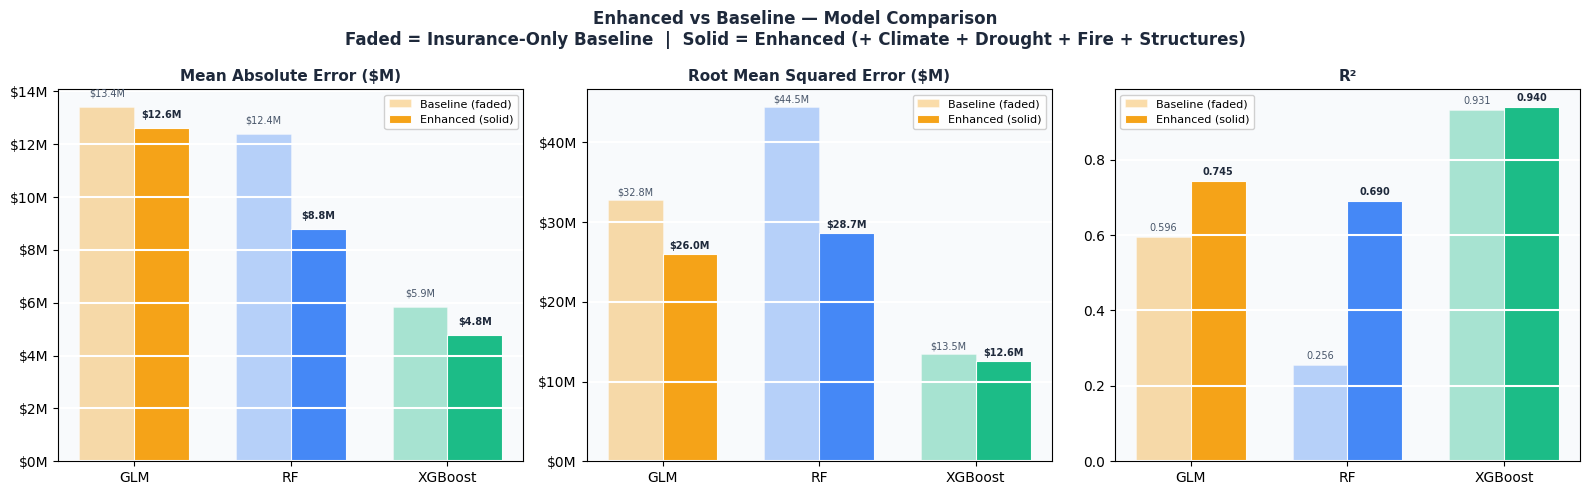


  enhanced_model_comparison.png


In [10]:
# ============================================================
# PLOT 1: Enhanced vs Baseline MAE/RMSE/R² Comparison
# ============================================================
COLORS = {
    "GLM":     "#F59E0B",
    "RF":      "#3B82F6",
    "XGBoost": "#10B981",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor("white")
fig.suptitle("Enhanced vs Baseline — Model Comparison\n"
             "Faded = Insurance-Only Baseline  |  "
             "Solid = Enhanced (+ Climate + Drought + Fire + Structures)",
             fontsize=12, fontweight="bold", color="#1E293B")

metrics_list = ["MAE", "RMSE", "R2"]
titles       = ["Mean Absolute Error ($M)",
                "Root Mean Squared Error ($M)", "R²"]

for ax, metric, title in zip(axes, metrics_list, titles):
    models = ["GLM", "RF", "XGBoost"]
    colors = [COLORS[m] for m in models]
    x      = np.arange(len(models))
    width  = 0.35

    enh_vals  = [r[metric] / 1e6 if metric != "R2"
                 else r[metric] for r in all_metrics]
    base_vals = ([BASELINE[m][metric] / 1e6 for m in models]
                 if metric != "R2"
                 else [BASELINE[m]["R2"] for m in models])

    b1 = ax.bar(x - width/2, base_vals, width,
                color=colors, alpha=0.35,
                edgecolor="white", linewidth=0.8)
    b2 = ax.bar(x + width/2, enh_vals,  width,
                color=colors, alpha=0.95,
                edgecolor="white", linewidth=0.8)

    fmt = ".3f" if metric == "R2" else ".1f"
    pfx = ""   if metric == "R2" else "$"
    sfx = ""   if metric == "R2" else "M"
    for bar, val in zip(b1, base_vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + (0.01 if metric == "R2" else 0.3),
                f"{pfx}{val:{fmt}}{sfx}",
                ha="center", va="bottom",
                fontsize=7, color="#475569")
    for bar, val in zip(b2, enh_vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + (0.01 if metric == "R2" else 0.3),
                f"{pfx}{val:{fmt}}{sfx}",
                ha="center", va="bottom",
                fontsize=7, color="#1E293B", fontweight="bold")

    if metric != "R2":
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda x, _: f"${x:.0f}M"))

    ax.set_xticks(x)
    ax.set_xticklabels(models, fontsize=10)
    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="y", color="white", linewidth=1.5, zorder=0)
    ax.set_title(title, fontsize=11, fontweight="bold", color="#1E293B")
    ax.legend(["Baseline (faded)", "Enhanced (solid)"],
              fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/enhanced_model_comparison.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("\n  enhanced_model_comparison.png")


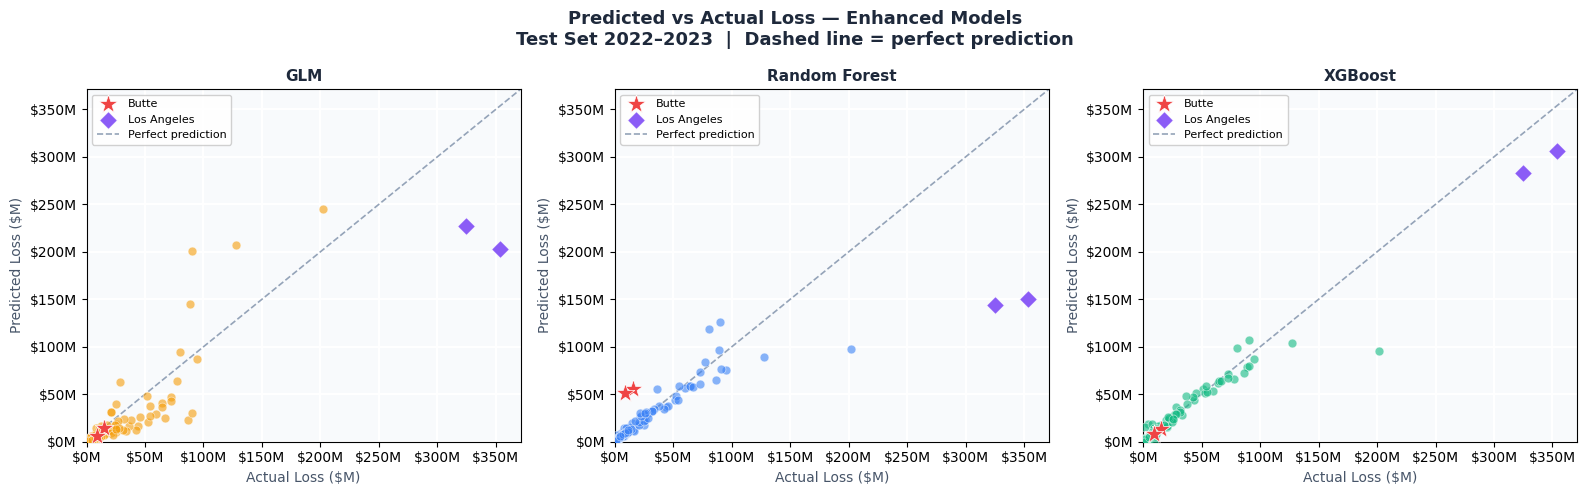

  enhanced_predicted_vs_actual.png


In [11]:
# ============================================================
# PLOT 2: Predicted vs Actual — Enhanced Models
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor("white")
fig.suptitle("Predicted vs Actual Loss — Enhanced Models\n"
             "Test Set 2022–2023  |  Dashed line = perfect prediction",
             fontsize=13, fontweight="bold", color="#1E293B")

for ax, pred_col, name, color in zip(
        axes,
        ["glm_pred", "rf_pred", "xgb_pred"],
        ["GLM", "Random Forest", "XGBoost"],
        [COLORS["GLM"], COLORS["RF"], COLORS["XGBoost"]]):

    actual_m = test[TARGET].values / 1e6
    pred_m   = test[pred_col].values / 1e6
    max_val  = max(actual_m.max(), pred_m.max()) * 1.05

    ax.scatter(actual_m, pred_m, color=color,
               alpha=0.6, s=40, edgecolors="white",
               linewidth=0.5, zorder=3)

    for county, mk, sz, col2 in [
            ("Butte",       "*", 200, "#EF4444"),
            ("Los Angeles", "D",  80, "#8B5CF6")]:
        mask = test["County"] == county
        if mask.any():
            ax.scatter(test.loc[mask, TARGET].values / 1e6,
                       test.loc[mask, pred_col].values / 1e6,
                       marker=mk, s=sz, zorder=5, color=col2,
                       edgecolors="white", linewidth=0.5,
                       label=county)

    ax.plot([0, max_val], [0, max_val], "--",
            color="#94A3B8", linewidth=1.2, zorder=2,
            label="Perfect prediction")
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.set_facecolor("#F8FAFC")
    ax.grid(color="white", linewidth=1.5, zorder=1)
    ax.set_xlabel("Actual Loss ($M)",    fontsize=10, color="#475569")
    ax.set_ylabel("Predicted Loss ($M)", fontsize=10, color="#475569")
    ax.set_title(name, fontsize=11, fontweight="bold", color="#1E293B")
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"${x:.0f}M"))
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"${x:.0f}M"))
    ax.legend(fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/enhanced_predicted_vs_actual.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  enhanced_predicted_vs_actual.png")

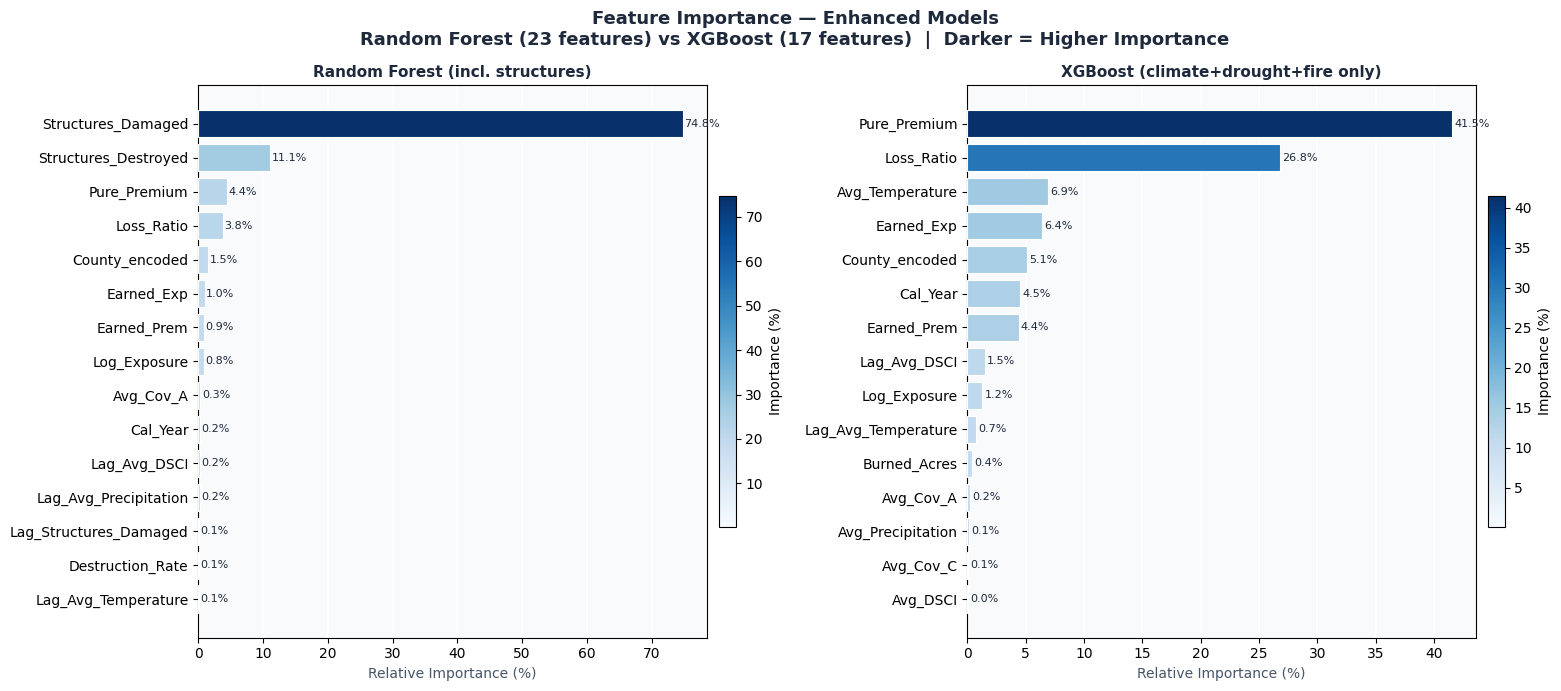

  enhanced_feature_importance.png


In [12]:
# ============================================================
# PLOT 3: Feature Importance — RF and XGBoost
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.patch.set_facecolor("white")
fig.suptitle("Feature Importance — Enhanced Models\n"
             "Random Forest (23 features) vs XGBoost (17 features)  "
             "|  Darker = Higher Importance",
             fontsize=13, fontweight="bold", color="#1E293B")

for ax, importance_df, name in zip(
        axes,
        [rf_importance, xgb_importance],
        ["Random Forest (incl. structures)",
         "XGBoost (climate+drought+fire only)"]):

    imp = importance_df.copy()
    imp["Importance"] = (imp["Importance"] /
                          imp["Importance"].sum() * 100)
    imp = imp.sort_values("Importance").tail(15)

    norm   = plt.Normalize(imp["Importance"].min(),
                           imp["Importance"].max())
    colors = cm.Blues(norm(imp["Importance"]) * 0.75 + 0.25)

    bars = ax.barh(imp["Feature"], imp["Importance"],
                   color=colors, edgecolor="white",
                   linewidth=0.8, zorder=3)
    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="x", color="white", linewidth=1.5, zorder=2)
    ax.set_xlabel("Relative Importance (%)",
                  fontsize=10, color="#475569")
    ax.set_title(name, fontsize=11,
                 fontweight="bold", color="#1E293B")

    for bar, val in zip(bars, imp["Importance"]):
        ax.text(bar.get_width() + 0.2,
                bar.get_y() + bar.get_height()/2,
                f"{val:.1f}%", va="center",
                fontsize=8, color="#1E293B")

    sm_cb = plt.cm.ScalarMappable(
        cmap="Blues",
        norm=plt.Normalize(imp["Importance"].min(),
                           imp["Importance"].max()))
    sm_cb.set_array([])
    plt.colorbar(sm_cb, ax=ax, label="Importance (%)",
                 shrink=0.6, pad=0.02)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/enhanced_feature_importance.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  enhanced_feature_importance.png")

Baseline predictions: (116, 8)
Enhanced predictions: (116, 7)
CA counties loaded: 58

Col 1 scale: $0 – $20.2M
Col 2 scale: ±$24.5M


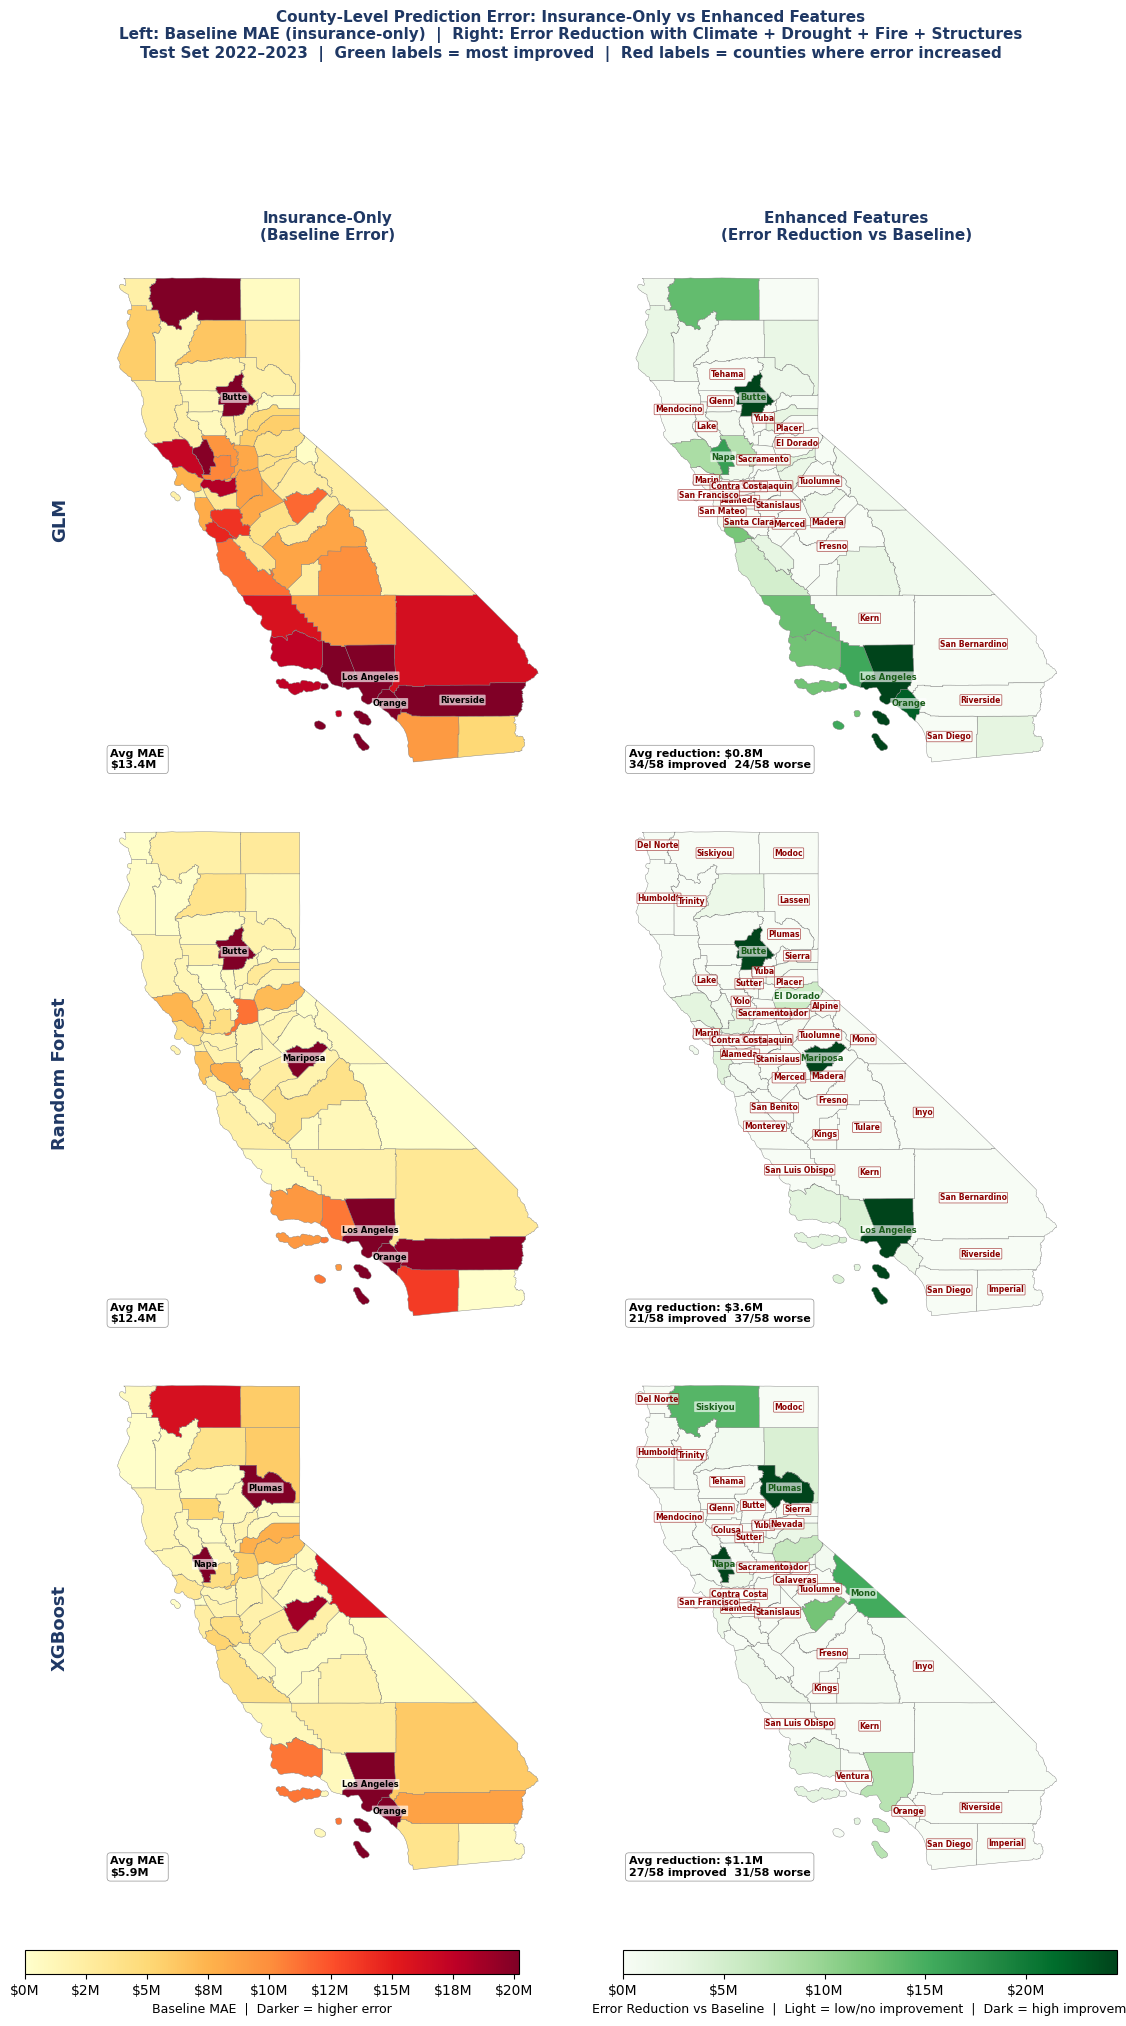

✅ Saved: <PROJECT_ROOT>/Data/../Plots/ca_map_6panel.png

COUNTY-LEVEL SUMMARY

Model              Base MAE    Enh MAE   Reduction   Improved    Worse
--------------------------------------------------------------------
  GLM            $   13.4M  $   12.6M  $     0.8M       34/58     24/58
  Random Forest  $   12.4M  $    8.8M  $     3.6M       21/58     37/58
  XGBoost        $    5.9M  $    4.8M  $     1.1M       27/58     31/58


In [14]:
# ============================================================
# CALIFORNIA MAP: 6-panel
# Col 1: Insurance-Only baseline error     — YlOrRd
# Col 2: Enhanced error reduction          — Greens (improvement)
# 3 rows: GLM | Random Forest | XGBoost
#
# Data sources:
#   baseline_predictions.csv  — insurance-only test predictions
#   enhanced_predictions.csv  — enhanced test predictions
#   TIGER county shapefile    — geometry
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.ticker import FuncFormatter
import pandas as pd
import numpy as np
import geopandas as gpd
import zipfile, os

# ── Paths ──────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE        = "./Data"
OUTPUT_DIR  = f"{BASE}/../Processed Data"
PLOT_DIR    = f"{BASE}/../Plots"
TIGER_ZIP   = (f"{BASE}/TIGER Shapefiles/tl_2025_us_county.zip")
os.makedirs(PLOT_DIR, exist_ok=True)

Y_TRUE = "Total_Wildfire_Loss"

# ── Load predictions ───────────────────────────────────────────
base_df = pd.read_csv(f"{OUTPUT_DIR}/baseline_predictions.csv")
enh_df  = pd.read_csv(f"{OUTPUT_DIR}/enhanced_predictions.csv")

print(f"Baseline predictions: {base_df.shape}")
print(f"Enhanced predictions: {enh_df.shape}")

# ── Load CA county shapefile ───────────────────────────────────
with zipfile.ZipFile(TIGER_ZIP, "r") as z:
    z.extractall("/tmp/tiger_counties")

counties = gpd.read_file("/tmp/tiger_counties/tl_2025_us_county.shp")
ca       = counties[counties["STATEFP"] == "06"].copy()
ca["County"] = ca["NAME"].str.strip()
ca = ca[["County", "geometry"]].to_crs(epsg=4326)

print(f"CA counties loaded: {len(ca)}")

# ── Helper: compute per-county MAE ────────────────────────────
def county_mae(df, pred_col, label):
    d = df.copy()
    d["abs_err"] = (d[pred_col] - d[Y_TRUE]).abs()
    return (d.groupby("County")["abs_err"]
             .mean().reset_index()
             .rename(columns={"abs_err": label}))

# ── Compute MAEs ───────────────────────────────────────────────
# Baseline (insurance-only)
glm_base = county_mae(base_df, "glm_pred",  "GLM_Base")
rf_base  = county_mae(base_df, "rf_pred",   "RF_Base")
xgb_base = county_mae(base_df, "xgb_pred",  "XGB_Base")

# Enhanced
glm_enh  = county_mae(enh_df,  "glm_pred",  "GLM_Enh")
rf_enh   = county_mae(enh_df,  "rf_pred",   "RF_Enh")
xgb_enh  = county_mae(enh_df,  "xgb_pred",  "XGB_Enh")

# ── Merge into geodataframe ────────────────────────────────────
geo = ca.copy()
for df, col in [(glm_base, "GLM_Base"), (rf_base,  "RF_Base"),
                (xgb_base, "XGB_Base"), (glm_enh,  "GLM_Enh"),
                (rf_enh,   "RF_Enh"),   (xgb_enh,  "XGB_Enh")]:
    geo = geo.merge(df, on="County", how="left")
geo = geo.fillna(0)

# Error reduction: positive = improved, negative = worse
geo["GLM_Red"] = geo["GLM_Base"] - geo["GLM_Enh"]
geo["RF_Red"]  = geo["RF_Base"]  - geo["RF_Enh"]
geo["XGB_Red"] = geo["XGB_Base"] - geo["XGB_Enh"]

# ── Color scales ───────────────────────────────────────────────
# Col 1: baseline error — shared scale across all 3 models
base_vals = pd.concat([geo["GLM_Base"], geo["RF_Base"], geo["XGB_Base"]])
vmax_base = np.percentile(base_vals[base_vals > 0], 92)
norm_base = Normalize(vmin=0, vmax=vmax_base)

# Col 2: error reduction — light green (low/no improvement) to
#         dark green (high improvement). Counties that worsened
#         (negative reduction) are clipped to 0 → lightest green.
red_vals = pd.concat([geo["GLM_Red"], geo["RF_Red"], geo["XGB_Red"]])
vmax_red = np.percentile(red_vals[red_vals > 0], 92)
norm_red = Normalize(vmin=0, vmax=vmax_red)

print(f"\nCol 1 scale: $0 – ${vmax_base/1e6:.1f}M")
print(f"Col 2 scale: ±${vmax_red/1e6:.1f}M")

# ── Label helpers ──────────────────────────────────────────────
def label_top_error(ax, gdf, col, n=4):
    """Label top n highest error counties."""
    for _, r in gdf[gdf[col] > 0].nlargest(n, col).iterrows():
        c = r.geometry.centroid
        ax.annotate(r["County"], (c.x, c.y),
                    fontsize=6, ha="center", va="center",
                    color="black", fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.1",
                              fc="white", alpha=0.65, lw=0))

def label_most_improved(ax, gdf, col, n=4):
    """Label top n most improved counties (largest positive reduction)."""
    for _, r in gdf[gdf[col] > 0].nlargest(n, col).iterrows():
        c = r.geometry.centroid
        ax.annotate(r["County"], (c.x, c.y),
                    fontsize=6, ha="center", va="center",
                    color="#1a5e1a", fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.1",
                              fc="white", alpha=0.65, lw=0))

def label_worsened(ax, gdf, col):
    """Label counties where enhanced features made things worse."""
    worse = gdf[gdf[col] < 0]
    for _, r in worse.iterrows():
        c = r.geometry.centroid
        ax.annotate(r["County"], (c.x, c.y),
                    fontsize=5.5, ha="center", va="center",
                    color="#8B0000", fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.1",
                              fc="white", alpha=0.7,
                              ec="#8B0000", lw=0.5))

# ── Figure layout ──────────────────────────────────────────────
rows_cfg = [
    ("GLM",           "GLM_Base", "GLM_Red"),
    ("Random Forest", "RF_Base",  "RF_Red"),
    ("XGBoost",       "XGB_Base", "XGB_Red"),
]

col_titles = [
    "Insurance-Only\n(Baseline Error)",
    "Enhanced Features\n(Error Reduction vs Baseline)",
]

fig, axes = plt.subplots(3, 2, figsize=(13, 20))
fig.patch.set_facecolor("white")

for row_i, (model, base_col, red_col) in enumerate(rows_cfg):

    # ── Col 1: Baseline error ───────────────────────────────────
    ax1 = axes[row_i, 0]
    ax1.set_facecolor("white")
    geo.plot(column=base_col, ax=ax1,
             cmap="YlOrRd", norm=norm_base,
             edgecolor="gray", linewidth=0.3,
             missing_kwds={"color": "#f0f0f0"})
    label_top_error(ax1, geo, base_col, n=4)

    avg_base = geo[base_col][geo[base_col] > 0].mean()
    ax1.text(0.03, 0.03,
             f"Avg MAE\n${avg_base/1e6:.1f}M",
             transform=ax1.transAxes, fontsize=8,
             color="black", fontweight="bold", va="bottom",
             bbox=dict(boxstyle="round,pad=0.3", fc="white",
                       alpha=0.85, ec="gray", lw=0.5))
    ax1.set_axis_off()

    # ── Col 2: Error reduction ──────────────────────────────────
    ax2 = axes[row_i, 1]
    ax2.set_facecolor("white")
    geo.plot(column=red_col, ax=ax2,
             cmap="Greens", norm=norm_red,
             edgecolor="gray", linewidth=0.3,
             missing_kwds={"color": "#f0f0f0"})

    # Label most improved in green, worsened in red
    label_most_improved(ax2, geo, red_col, n=4)
    label_worsened(ax2, geo, red_col)

    improved = (geo[red_col] > 0).sum()
    worsened = (geo[red_col] < 0).sum()
    avg_red  = geo[red_col].mean()
    ax2.text(0.03, 0.03,
             f"Avg reduction: ${avg_red/1e6:.1f}M\n"
             f"{improved}/58 improved  {worsened}/58 worse",
             transform=ax2.transAxes, fontsize=8,
             color="black", fontweight="bold", va="bottom",
             bbox=dict(boxstyle="round,pad=0.3", fc="white",
                       alpha=0.85, ec="gray", lw=0.5))
    ax2.set_axis_off()

    # ── Row label ───────────────────────────────────────────────
    axes[row_i, 0].text(
        -0.06, 0.5, model,
        transform=axes[row_i, 0].transAxes,
        fontsize=13, fontweight="bold",
        color="#1F3864", va="center",
        ha="right", rotation=90)

    # ── Col titles (top row only) ───────────────────────────────
    if row_i == 0:
        for col_i, title in enumerate(col_titles):
            axes[0, col_i].set_title(
                title, fontsize=11, fontweight="bold",
                color="#1F3864", pad=10)

# ── Colorbars ──────────────────────────────────────────────────
sm1 = cm.ScalarMappable(cmap="YlOrRd", norm=norm_base)
sm1.set_array([])
cb1_ax = fig.add_axes([0.08, 0.02, 0.38, 0.012])
cb1    = plt.colorbar(sm1, cax=cb1_ax, orientation="horizontal")
cb1.set_label("Baseline MAE  |  Darker = higher error",
              color="black", fontsize=9)
cb1.ax.xaxis.set_tick_params(color="black", labelcolor="black")
cb1.formatter = FuncFormatter(lambda x, _: f"${x/1e6:.0f}M")
cb1.update_ticks()

sm2 = cm.ScalarMappable(cmap="Greens", norm=norm_red)
sm2.set_array([])
cb2_ax = fig.add_axes([0.54, 0.02, 0.38, 0.012])
cb2    = plt.colorbar(sm2, cax=cb2_ax, orientation="horizontal")
cb2.set_label(
    "Error Reduction vs Baseline  |  Light = low/no improvement  |  Dark = high improvement",
    color="black", fontsize=9)
cb2.ax.xaxis.set_tick_params(color="black", labelcolor="black")
cb2.formatter = FuncFormatter(lambda x, _: f"${x/1e6:.0f}M")
cb2.update_ticks()

# ── Title ──────────────────────────────────────────────────────
fig.suptitle(
    "County-Level Prediction Error: Insurance-Only vs Enhanced Features\n"
    "Left: Baseline MAE (insurance-only)  |  "
    "Right: Error Reduction with Climate + Drought + Fire + Structures\n"
    "Test Set 2022–2023  |  "
    "Green labels = most improved  |  Red labels = counties where error increased",
    fontsize=11, fontweight="bold", color="#1F3864", y=1.002)

plt.subplots_adjust(hspace=0.04, wspace=0.06, bottom=0.06)
plt.savefig(f"{PLOT_DIR}/ca_map_6panel.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Saved: {PLOT_DIR}/ca_map_6panel.png")

# ── Summary table ──────────────────────────────────────────────
print("\n" + "=" * 65)
print("COUNTY-LEVEL SUMMARY")
print("=" * 65)
print(f"\n{'Model':<16} {'Base MAE':>10} {'Enh MAE':>10} "
      f"{'Reduction':>11} {'Improved':>10} {'Worse':>8}")
print("-" * 68)
for model, base_col, red_col in rows_cfg:
    enh_col  = base_col.replace("Base", "Enh")
    base_avg = geo[base_col][geo[base_col] > 0].mean()
    enh_avg  = geo[enh_col][geo[enh_col]   > 0].mean()
    avg_red  = geo[red_col].mean()
    improved = (geo[red_col] > 0).sum()
    worsened = (geo[red_col] < 0).sum()
    print(f"  {model:<14} ${base_avg/1e6:>7.1f}M  "
          f"${enh_avg/1e6:>7.1f}M  "
          f"${avg_red/1e6:>8.1f}M  "
          f"{improved:>7}/58  {worsened:>5}/58")


Generating 2-panel XGBoost map...


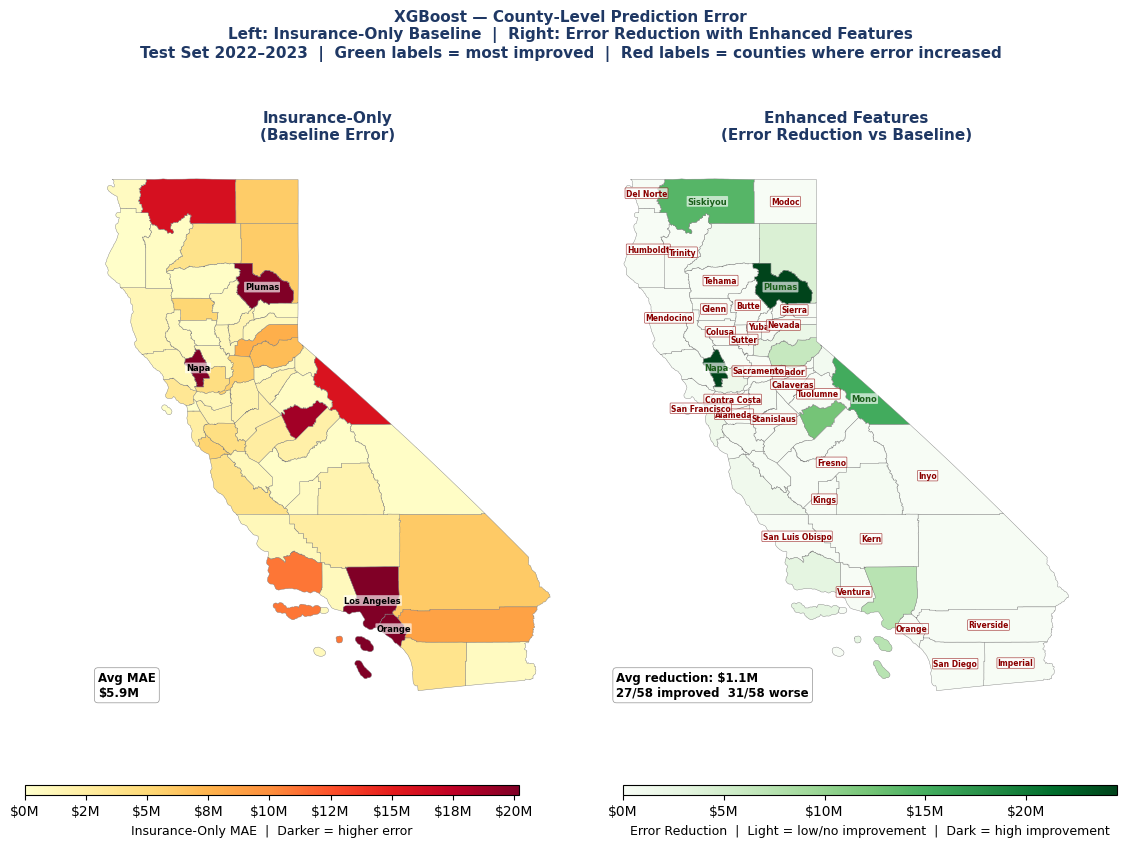

✅ Saved: <PROJECT_ROOT>/Data/../Plots/ca_map_xgb_2panel.png


In [17]:

# ============================================================
# 2-PANEL MAP — XGBoost only
# Left:  Insurance-only error (YlOrRd)
# Right: Enhanced error reduction (Greens)
# ============================================================
print("\nGenerating 2-panel XGBoost map...")

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
fig.patch.set_facecolor("white")

panels_xgb = [
    (axes[0], "XGB_Base", "YlOrRd", norm_base,
     "Insurance-Only\n(Baseline Error)"),
    (axes[1], "XGB_Red",  "Greens", norm_red,
     "Enhanced Features\n(Error Reduction vs Baseline)"),
]

for ax, col, cmap, norm, title in panels_xgb:
    ax.set_facecolor("white")
    geo.plot(column=col, ax=ax,
             cmap=cmap, norm=norm,
             edgecolor="gray", linewidth=0.3,
             missing_kwds={"color": "#f0f0f0"})

    if col == "XGB_Base":
        label_top_error(ax, geo, col, n=4)
        avg  = geo[col][geo[col] > 0].mean()
        stats_txt = f"Avg MAE\n${avg/1e6:.1f}M"
    else:
        label_most_improved(ax, geo, col, n=4)
        label_worsened(ax, geo, col)
        improved  = (geo[col] > 0).sum()
        worsened  = (geo[col] < 0).sum()
        avg       = geo[col].mean()
        stats_txt = (f"Avg reduction: ${avg/1e6:.1f}M\n"
                     f"{improved}/58 improved  "
                     f"{worsened}/58 worse")

    ax.text(0.03, 0.03, stats_txt,
            transform=ax.transAxes, fontsize=8.5,
            color="black", fontweight="bold", va="bottom",
            bbox=dict(boxstyle="round,pad=0.3", fc="white",
                      alpha=0.85, ec="gray", lw=0.5))
    ax.set_title(title, fontsize=11,
                 fontweight="bold", color="#1F3864", pad=10)
    ax.set_axis_off()

# ── Colorbars ──────────────────────────────────────────────────
sm1 = cm.ScalarMappable(cmap="YlOrRd", norm=norm_base)
sm1.set_array([])
cb1_ax = fig.add_axes([0.08, 0.02, 0.38, 0.012])
cb1    = plt.colorbar(sm1, cax=cb1_ax, orientation="horizontal")
cb1.set_label("Insurance-Only MAE  |  Darker = higher error",
              color="black", fontsize=9)
cb1.ax.xaxis.set_tick_params(color="black", labelcolor="black")
cb1.formatter = FuncFormatter(lambda x, _: f"${x/1e6:.0f}M")
cb1.update_ticks()

sm2 = cm.ScalarMappable(cmap="Greens", norm=norm_red)
sm2.set_array([])
cb2_ax = fig.add_axes([0.54, 0.02, 0.38, 0.012])
cb2    = plt.colorbar(sm2, cax=cb2_ax, orientation="horizontal")
cb2.set_label(
    "Error Reduction  |  "
    "Light = low/no improvement  |  Dark = high improvement",
    color="black", fontsize=9)
cb2.ax.xaxis.set_tick_params(color="black", labelcolor="black")
cb2.formatter = FuncFormatter(lambda x, _: f"${x/1e6:.0f}M")
cb2.update_ticks()

fig.suptitle(
    "XGBoost — County-Level Prediction Error\n"
    "Left: Insurance-Only Baseline  |  "
    "Right: Error Reduction with Enhanced Features\n"
    "Test Set 2022–2023  |  "
    "Green labels = most improved  |  "
    "Red labels = counties where error increased",
    fontsize=11, fontweight="bold", color="#1F3864", y=1.002)

plt.subplots_adjust(hspace=0.04, wspace=0.06, bottom=0.06)
plt.savefig(f"{PLOT_DIR}/ca_map_xgb_2panel.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Saved: {PLOT_DIR}/ca_map_xgb_2panel.png")